# Calibration across noise domains

Supplementary results

In [1]:
from pathlib import Path
import sys
from IPython.display import display, HTML
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'configs/noise.json').exists())
sys.path.insert(0,str(ROOT/'src'))
from gw import classification_report as report
config=report.read(ROOT,'noise')
reference=report.paper(ROOT,'s3_noise')
directory=ROOT/'results/noise/gpu_predictions'
runs,mean,sd=report.calculate(ROOT,config,directory)
from gw.publication_ui import folded_table, folded_comparison, compact_settings

## Results

Test set · 10 seeds per condition · mean ± sample SD.

In [2]:
report.show(report.table_frame(mean, sd, reference))

## Calibration

Diamonds: mean; bars: sample SD; circles: individual seeds.

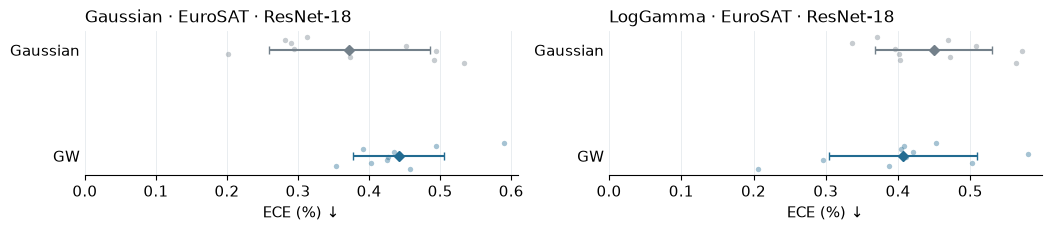

In [3]:
figure = report.plot(runs, mean, sd, ROOT / 'assets/figures/noise_ece.png')
display(figure)
import matplotlib.pyplot as plt
plt.close(figure)

## Reference values

Recomputed from saved per-image test predictions.

In [4]:
check = report.comparison(mean, sd, reference)
folded_comparison(check)

## Inference

Set `RUN_INFERENCE = True` to evaluate the checkpoints.

In [5]:
from gw import noise_inference
RUN_INFERENCE=False
if RUN_INFERENCE:
    directory=noise_inference.run(ROOT,config,device='auto')
    runs,mean,sd=report.calculate(ROOT,config,directory)
    report.show(report.table_frame(mean,sd,reference))

## Training

Set `RUN_TRAINING = True` to train one seed and condition. Checkpoint choice uses validation NLL.

In [6]:
from gw import noise_training
TRAIN_RUN='000'
RUN_TRAINING=False
if RUN_TRAINING:
    training_run=next(r for r in config['runs'] if r['id']==TRAIN_RUN)
    training_output=noise_training.run(ROOT,training_run,device='auto')
    print(training_output)

## Settings

In [7]:
display(HTML('<details><summary>Settings</summary><div style="overflow:auto;max-height:420px">'+report.settings(config).to_html(border=0)+'</div></details>'))
display(HTML('<details><summary>Data and model</summary>EuroSAT RGB · 64 × 64 · 18,900 training / 4,050 validation / 4,050 test images · ResNet-18 with a 3 × 3 stem · training-channel normalization · five fixed test realizations · pooled ECE-15 · uniform soft warm-up labels · SGD momentum retained · minimum validation NLL checkpoint</details>'))

## Paired interaction

In [8]:
from pathlib import Path
import sys
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'configs/random.json').exists())
sys.path.insert(0,str(ROOT/'src'))
from gw import supporting_reports as report
from gw.classification_report import show
import matplotlib.pyplot as plt

## Results

10 paired seeds · ECE differences in percentage points · 95% t intervals.

In [9]:
directory=ROOT/'results/noise/gpu_predictions'
raw,summary=report.interaction(ROOT,directory)
show(summary, {'Mean (pp)':'{:.4f}', 'CI low':'{:.4f}', 'CI high':'{:.4f}'})

,Mean (pp),CI low,CI high,Negative seeds
Comparison,,,,
Gaussian domain,0.0694,-0.0336,0.1724,4
LogGamma domain,-0.0424,-0.1501,0.0654,6
Interaction,-0.1118,-0.2199,-0.0037,7


## Paired differences

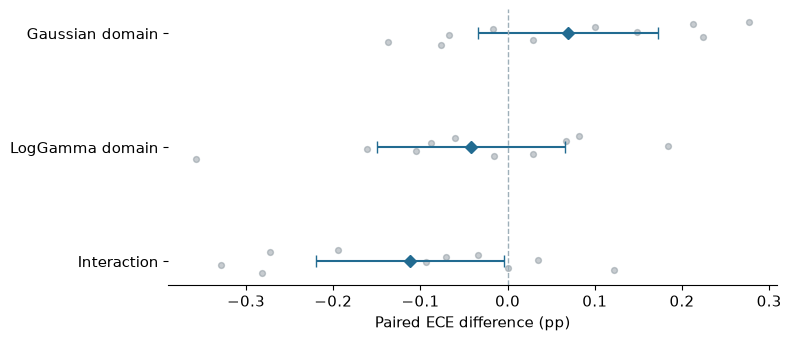

In [10]:
figure=report.interaction_plot(raw,summary,ROOT/'assets/figures/noise_interaction.png')
display(figure)
plt.close(figure)

## Reference values

In [11]:
import json
import pandas as pd
paper=json.loads((ROOT/'results/paper/s3_interaction.json').read_text())['rows']
comparison=[]
for name,row in summary.iterrows():
    p=paper[name]
    comparison.append({'Comparison':name,'Paper mean (pp)':f"{p['mean']:.4f}",'Recomputed mean (pp)':f"{row['Mean (pp)']:.4f}",'Paper 95% CI':f"[{p['low']:.4f}, {p['high']:.4f}]",'Recomputed 95% CI':f"[{row['CI low']:.4f}, {row['CI high']:.4f}]"})
show(pd.DataFrame(comparison).set_index('Comparison'))

,Paper mean (pp),Recomputed mean (pp),Paper 95% CI,Recomputed 95% CI
Comparison,,,,
Gaussian domain,0.0696,0.0694,"[-0.0331, 0.1723]","[-0.0336, 0.1724]"
LogGamma domain,-0.0423,-0.0424,"[-0.1506, 0.0660]","[-0.1501, 0.0654]"
Interaction,-0.1119,-0.1118,"[-0.2212, -0.0026]","[-0.2199, -0.0037]"


## Definition

Within each domain, difference = ECE(GW) − ECE(Gaussian warm-up). Interaction = difference(LogGamma domain) − difference(Gaussian domain).

## Per-seed results

In [12]:
show(raw, {column:'{:.4f}' for column in raw.columns})

,Gaussian domain,LogGamma domain,Interaction
Seed,,,
2026071501,0.2771,0.0823,-0.1948
2026071502,0.2128,-0.0598,-0.2726
2026071503,0.1008,0.0671,-0.0337
2026071504,-0.0173,-0.0877,-0.0705
2026071505,0.1488,0.1836,0.0348
2026071506,-0.0671,-0.1611,-0.0941
2026071507,0.2237,-0.1050,-0.3287
2026071508,0.0287,0.0296,0.0009
2026071509,-0.1373,-0.0153,0.1220
